In [2]:
import os
import sys

project_root = os.path.abspath("..")   # if the notebook is inside notebooks/
sys.path.insert(0, project_root)
print(project_root)

c:\Projects\Service Event Framework\Improvement\code


In [46]:
import os
import numpy as np
import pandas as pd
from utils.dbconnection import engine
from utils.config import config
from pathlib import Path
from matplotlib import pyplot as plt
import seaborn as sns

In [4]:
file_name = 'ServiceEvent_Material.sql'
sql_path = os.path.join(config.locations.queries_folder, file_name)
df = pd.read_sql_query(open(sql_path, "r").read(), engine)
df.head()

,DServiceEventID,Serviceeventcode,ServiceEventName,AND_OR,Priority,confidence,Itemnumber,MaterialName,MaterialGroup,MaterialGroupDescription
0,1,BladeBearingReplace,Blade Bearing Replacement,OR,9.6,10.0,107033,BLADE BEARING ø54,31,"Bearings, Blade TRAC"
1,1,BladeBearingReplace,Blade Bearing Replacement,OR,9.6,10.0,760306,BLADE BEARING MODULE,327,Nacelle modules and
2,1,BladeBearingReplace,Blade Bearing Replacement,OR,9.6,10.0,76221907,BLADE BEARING MODULE,30,Bearings
3,1,BladeBearingReplace,Blade Bearing Replacement,OR,9.6,10.0,76221971,BLADE BEARING MODULE,327,Nacelle modules and
4,4,GenBearReplace,Generator Bearing Replacement,OR,7.8,10.0,103566,"BEARING,BALL,6344 MC3,220 mm",30,Bearings


In [60]:
df.loc[df['MaterialGroup']=='N/A'].shape

(34, 10)

In [62]:
df = df.loc[df['MaterialGroup']!='N/A']

Does all materials in events belong to same material group?

In [63]:
req_cols = ['Serviceeventcode', 'MaterialGroup', 'MaterialGroupDescription']
df_req = df[req_cols].drop_duplicates(ignore_index=True)
df_req.head()

,Serviceeventcode,MaterialGroup,MaterialGroupDescription
0,BladeBearingReplace,31,"Bearings, Blade TRAC"
1,BladeBearingReplace,327,Nacelle modules and
2,BladeBearingReplace,30,Bearings
3,GenBearReplace,30,Bearings
4,GenBearReplace,222,Generator accessorie


In [64]:
# Count the material groups

mgg1 = df_req.groupby('Serviceeventcode').agg({'MaterialGroup': 'count'})
mgg1 = mgg1.reset_index()
mgg1.head()

,Serviceeventcode,MaterialGroup
0,AGODCChopperResistorReplace,3
1,APSCTModule_mat,1
2,APSContactor_mat,1
3,APSFuse_mat,1
4,APSIOCardUPS_mat,1


In [65]:
mgg1.sort_values(by='MaterialGroup', ascending=False).head(10)

,Serviceeventcode,MaterialGroup
93,ConvertorModReplace,12
131,GearHSS,9
410,TowerFlangeStudBoltReplace,7
208,HydPumpReplace,7
471,YawGreaseWheel_mat,7
211,HydSystemSealMaterial,6
343,RotatingTransferUnitReplace,6
333,PowSupplyCompReplace,6
391,TowerAccelerometer_mat,6
165,GenBrushReplace,6


In [66]:
mgg1.loc[mgg1['MaterialGroup']== 1].shape, mgg1.loc[mgg1['MaterialGroup']> 1].shape

((283, 2), (198, 2))

In [67]:
mgg1['MaterialGroup'].describe()

count    481.000000
mean       1.817048
std        1.349306
min        1.000000
25%        1.000000
50%        1.000000
75%        2.000000
max       12.000000
Name: MaterialGroup, dtype: float64

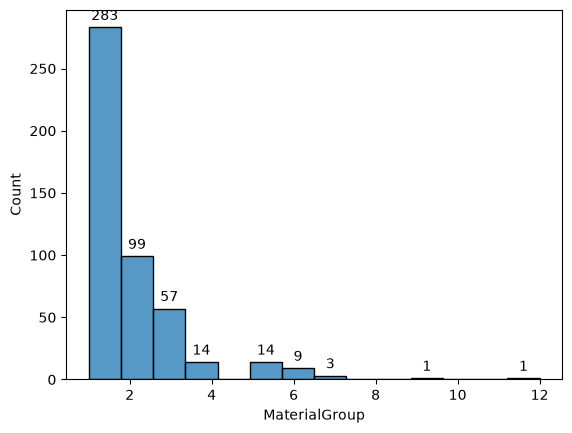

In [68]:
mgg1f = mgg1.loc[mgg1['MaterialGroup']<14]
ax = sns.histplot(mgg1f['MaterialGroup'], bins=14, kde=False)
for bars in ax.containers:
    for bar in bars:
        height = bar.get_height()
        if height > 0:
            ax.annotate(
                f'{int(height)}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),
                textcoords='offset points',
                ha='center',
                va='bottom',
            )

In [69]:
req_cols2 = ['Serviceeventcode', 'MaterialGroup', 'MaterialGroupDescription']
mggf2 = df_req.loc[df_req['Serviceeventcode'].isin(mgg1.loc[(mgg1['MaterialGroup']>=2)&(mgg1['MaterialGroup']<7),'Serviceeventcode']), req_cols2].drop_duplicates()
mggf2.sort_values(by='Serviceeventcode', inplace=True)
mggf2.head()

,Serviceeventcode,MaterialGroup,MaterialGroupDescription
682,AGODCChopperResistorReplace,165,"Elec CT modules, act"
683,AGODCChopperResistorReplace,425,Resistors
684,AGODCChopperResistorReplace,175,Engineering elements
717,APSPowerSupplyTransformerReplace,275,"Kit set/sub assy, el"
718,APSPowerSupplyTransformerReplace,470,Slip rings


In [86]:
def get_mg_n(n=1):
    req_cols2 = ['Serviceeventcode', 'MaterialGroup', 'MaterialGroupDescription']
    mggf2 = df_req.loc[df_req['Serviceeventcode'].isin(mgg1.loc[(mgg1['MaterialGroup']==n),'Serviceeventcode']), req_cols2].drop_duplicates()
    mggf2.sort_values(by='Serviceeventcode', inplace=True)
    mggf2 = mggf2.merge(df[req_cols2+['Itemnumber','MaterialName']], on=req_cols2, how='left')
    return mggf2

In [78]:
df_req.loc[df_req['Serviceeventcode']=='ConvertorModReplace']

,Serviceeventcode,MaterialGroup,MaterialGroupDescription
169,ConvertorModReplace,377,Power convertion pan
170,ConvertorModReplace,310,Modules
171,ConvertorModReplace,185,"Filters, oil & hydra"
172,ConvertorModReplace,195,Frequency converter
173,ConvertorModReplace,420,"Relay, electronic"
174,ConvertorModReplace,375,PLC systems
175,ConvertorModReplace,535,Transistors
176,ConvertorModReplace,515,Thyristors
177,ConvertorModReplace,380,Power Supply
178,ConvertorModReplace,97,Controller & distrib


Save results

In [88]:
mg_dict = {
    '1mgs': get_mg_n(1),
    '2mgs': get_mg_n(2),
    '3mgs': get_mg_n(3),
    '4mgs': get_mg_n(4),
    '5mgs': get_mg_n(5),
    '6mgs': get_mg_n(6),
    '7mgs': get_mg_n(7),
    '9mgs': get_mg_n(9),
    '12mgs': get_mg_n(12)
}

In [90]:
output_dir = Path(config.locations.outputs)
output_dir.mkdir(parents=True, exist_ok=True)
excel_path = output_dir / "multiple_materialGroups_analysis.xlsx"

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    for sheet_name, df_sheet in mg_dict.items():
        if isinstance(df_sheet, pd.DataFrame):
            df_sheet.to_excel(writer, sheet_name=sheet_name, index=False)
        else:
            pd.DataFrame(df_sheet).to_excel(writer, sheet_name=sheet_name, index=False)

excel_path

Exception ignored while calling deallocator <function ZipFile.__del__ at 0x0000021E34B4C040>:
Traceback (most recent call last):
  File "c:\Users\SRVID\.conda\envs\build_app\Lib\zipfile\__init__.py", line 2078, in __del__
    self.close()
  File "c:\Users\SRVID\.conda\envs\build_app\Lib\zipfile\__init__.py", line 2095, in close
    self.fp.seek(self.start_dir)
ValueError: seek of closed file


WindowsPath('C:/Projects/Service Event Framework/Improvement/code/data/outputs/multiple_materialGroups_analysis.xlsx')